In [1]:
!pip install -q -U ultralytics kaggle

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 3.2 MB/s eta 0:00:00


In [2]:
import os
import shutil
import random
import glob
import numpy as np
import matplotlib.pyplot as plt

from getpass import getpass

In [3]:
KAGGLE_API_TOKEN = getpass("Enter your Kaggle API Token: ")

os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

print("Kaggle API token set successfully.")

Enter your Kaggle API Token: ··········
Kaggle API token set successfully.


In [4]:
!kaggle datasets list -s waste-classification-data

ref                                                                   title                                                   size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------------  ------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
techsash/waste-classification-data                                    Waste Classification data                          447914276  2019-06-16 03:24:52.733000          61415        609  0.875            
sapal6/waste-classification-data-v2                                   Waste Classification Data v2                       236799849  2019-11-29 03:47:08.897000           3146         35  0.5625           
joebeachcapital/realwaste                                             RealWaste Image Classification                     688660611  2024-01-19 03:47:23.723000           7222         51

In [5]:
!kaggle datasets download -d techsash/waste-classification-data -p /content

Dataset URL: https://www.kaggle.com/datasets/techsash/waste-classification-data
License(s): CC-BY-SA-4.0
100% 427M/427M [00:22<00:00, 19.5MB/s]



In [6]:
import zipfile
import os

zip_path = "/content/waste-classification-data.zip"
extract_path = "/content/waste_dataset"

if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [7]:
for root, dirs, files in os.walk("/content/waste_dataset"):
    if os.path.basename(root).upper() in ["TRAIN", "TEST"]:
        print(root)

/content/waste_dataset/DATASET/TRAIN
/content/waste_dataset/DATASET/TEST
/content/waste_dataset/dataset/DATASET/TRAIN
/content/waste_dataset/dataset/DATASET/TEST


In [8]:
original_train = "/content/waste_dataset/DATASET/TRAIN"
original_test  = "/content/waste_dataset/DATASET/TEST"

print("TRAIN exists:", os.path.exists(original_train))
print("TEST exists :", os.path.exists(original_test))

TRAIN exists: True
TEST exists : True


In [9]:
print("TRAIN folders:")
print(os.listdir(original_train))

print("\nTEST folders:")
print(os.listdir(original_test))

TRAIN folders:
['R', 'O']

TEST folders:
['R', 'O']


In [10]:
def count_images(folder):
    extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

    count = 0

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(extensions):
                count += 1

    return count


print("Original TRAIN images:", count_images(original_train))
print("Original TEST images :", count_images(original_test))

print("\nTRAIN/O:", count_images(os.path.join(original_train, "O")))
print("TRAIN/R:", count_images(os.path.join(original_train, "R")))

print("\nTEST/O:", count_images(os.path.join(original_test, "O")))
print("TEST/R:", count_images(os.path.join(original_test, "R")))

Original TRAIN images: 22564
Original TEST images : 2513

TRAIN/O: 12565
TRAIN/R: 9999

TEST/O: 1401
TEST/R: 1112


In [11]:
yolo_dataset = "/content/yolo26_waste"

if os.path.exists(yolo_dataset):
    shutil.rmtree(yolo_dataset)

classes = [
    "BIODEGRADABLE",
    "NON_BIODEGRADABLE"
]

for split in ["train", "val", "test"]:
    for cls in classes:
        os.makedirs(
            os.path.join(yolo_dataset, split, cls),
            exist_ok=True
        )

print("YOLO26 dataset folders created!")

YOLO26 dataset folders created!


In [12]:
random.seed(42)

def get_images(folder):
    extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

    return [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(extensions)
    ]


# -------------------------
# ORGANIC → BIODEGRADABLE
# -------------------------

organic_images = get_images(
    os.path.join(original_train, "O")
)

random.shuffle(organic_images)

split_index = int(0.8 * len(organic_images))

organic_train = organic_images[:split_index]
organic_val   = organic_images[split_index:]


# -------------------------
# RECYCLABLE → NON-BIODEGRADABLE
# -------------------------

recyclable_images = get_images(
    os.path.join(original_train, "R")
)

random.shuffle(recyclable_images)

split_index = int(0.8 * len(recyclable_images))

recyclable_train = recyclable_images[:split_index]
recyclable_val   = recyclable_images[split_index:]


print("Organic:")
print("Train:", len(organic_train))
print("Val  :", len(organic_val))

print("\nRecyclable:")
print("Train:", len(recyclable_train))
print("Val  :", len(recyclable_val))

Organic:
Train: 10052
Val  : 2513

Recyclable:
Train: 7999
Val  : 2000


In [13]:
def copy_images(image_list, destination):
    for image_path in image_list:
        shutil.copy2(
            image_path,
            os.path.join(
                destination,
                os.path.basename(image_path)
            )
        )


# Organic → BIODEGRADABLE

copy_images(
    organic_train,
    os.path.join(
        yolo_dataset,
        "train",
        "BIODEGRADABLE"
    )
)

copy_images(
    organic_val,
    os.path.join(
        yolo_dataset,
        "val",
        "BIODEGRADABLE"
    )
)


# Recyclable → NON-BIODEGRADABLE

copy_images(
    recyclable_train,
    os.path.join(
        yolo_dataset,
        "train",
        "NON_BIODEGRADABLE"
    )
)

copy_images(
    recyclable_val,
    os.path.join(
        yolo_dataset,
        "val",
        "NON_BIODEGRADABLE"
    )
)

print("Train and validation images copied!")

Train and validation images copied!


In [14]:
# O → BIODEGRADABLE

test_organic = get_images(
    os.path.join(original_test, "O")
)

copy_images(
    test_organic,
    os.path.join(
        yolo_dataset,
        "test",
        "BIODEGRADABLE"
    )
)


# R → NON-BIODEGRADABLE

test_recyclable = get_images(
    os.path.join(original_test, "R")
)

copy_images(
    test_recyclable,
    os.path.join(
        yolo_dataset,
        "test",
        "NON_BIODEGRADABLE"
    )
)

print("Test images copied!")

Test images copied!


In [15]:
for split in ["train", "val", "test"]:

    print("\n", split.upper())

    for cls in classes:

        folder = os.path.join(
            yolo_dataset,
            split,
            cls
        )

        print(
            cls,
            ":",
            count_images(folder)
        )


 TRAIN
BIODEGRADABLE : 10052
NON_BIODEGRADABLE : 7999

 VAL
BIODEGRADABLE : 2513
NON_BIODEGRADABLE : 2000

 TEST
BIODEGRADABLE : 1401
NON_BIODEGRADABLE : 1112


In [16]:
for root, dirs, files in os.walk(yolo_dataset):

    level = root.replace(
        yolo_dataset, ""
    ).count(os.sep)

    indent = "    " * level

    print(
        f"{indent}{os.path.basename(root)}/"
    )

yolo26_waste/
    test/
        NON_BIODEGRADABLE/
        BIODEGRADABLE/
    train/
        NON_BIODEGRADABLE/
        BIODEGRADABLE/
    val/
        NON_BIODEGRADABLE/
        BIODEGRADABLE/


In [17]:
from ultralytics import YOLO

print("Ultralytics imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics imported successfully!


In [18]:
model = YOLO("yolo26n-cls.pt")

In [19]:
results = model.train(
    data=yolo_dataset,
    epochs=30,
    imgsz=224,
    batch=32,
    patience=8,
    device=0,
    project="/content/yolo26_results",
    name="waste_classification",
    pretrained=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo26_waste, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=waste_classification, nbs=64, nms=Fa

In [20]:
best_model_path = "/content/yolo26_results/waste_classification/weights/best.pt"

print("Best model exists:",
      os.path.exists(best_model_path))

Best model exists: True


In [21]:
best_model = YOLO(best_model_path)

In [22]:
val_metrics = best_model.val(
    data=yolo_dataset,
    split="val"
)

print("\nVALIDATION RESULTS")
print("------------------")

print(
    f"Top-1 Accuracy: "
    f"{val_metrics.top1 * 100:.2f}%"
)

print(
    f"Top-5 Accuracy: "
    f"{val_metrics.top5 * 100:.2f}%"
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs
train: /content/yolo26_waste/train... found 18051 images in 2 classes ✅ 
val: /content/yolo26_waste/val... found 4513 images in 2 classes ✅ 
test: /content/yolo26_waste/test... found 2513 images in 2 classes ✅ 
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 470.0±244.2 MB/s, size: 8.5 KB)
val: Scanning /content/yolo26_waste/val... 4513 images, 0 corrupt: 100% ━━━━━━━━━━━━ 4513/4513 1.7Git/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 283/283 21.4it/s 13.2s
                   all      0.954          1
Speed: 0.1ms preprocess, 1.1ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val

VALIDATION RESULTS
------------------
Top-1 Accuracy: 95.37%
Top-5 Accuracy: 100.00%


In [23]:
test_metrics = best_model.val(
    data=yolo_dataset,
    split="test"
)

print("\nTEST RESULTS")
print("------------")

print(
    f"Test Top-1 Accuracy: "
    f"{test_metrics.top1 * 100:.2f}%"
)

print(
    f"Test Top-5 Accuracy: "
    f"{test_metrics.top5 * 100:.2f}%"
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
train: /content/yolo26_waste/train... found 18051 images in 2 classes ✅ 
val: /content/yolo26_waste/val... found 4513 images in 2 classes ✅ 
test: /content/yolo26_waste/test... found 2513 images in 2 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 321.9±149.3 MB/s, size: 11.9 KB)
test: Scanning /content/yolo26_waste/test... 2513 images, 0 corrupt: 100% ━━━━━━━━━━━━ 2513/2513 6.8Kit/s 0.4s
test: New cache created: /content/yolo26_waste/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 158/158 21.3it/s 7.4s
                   all       0.91          1
Speed: 0.1ms preprocess, 1.1ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val-2

TEST RESULTS
------------
Test Top-1 Accuracy: 90.97%
Test Top-5 Accuracy: 100.00%


In [24]:
test_images = glob.glob(
    yolo_dataset + "/test/*/*"
)

test_images = [
    x for x in test_images
    if x.lower().endswith(
        (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    )
]

print("Total test images:", len(test_images))

Total test images: 2513


In [25]:
test_results = best_model.predict(
    source=test_images,
    save=True,
    verbose=False
)

print("Test predictions completed!")

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /content/runs/classify/predict
Test predictions completed!


In [26]:
for result in test_results[:10]:

    class_id = result.probs.top1
    confidence = float(result.probs.top1conf)

    class_name = result.names[class_id]

    print(
        f"Prediction: {class_name} | "
        f"Confidence: {confidence * 100:.2f}%"
    )

Prediction: BIODEGRADABLE | Confidence: 95.05%
Prediction: NON_BIODEGRADABLE | Confidence: 99.40%
Prediction: NON_BIODEGRADABLE | Confidence: 85.36%
Prediction: NON_BIODEGRADABLE | Confidence: 66.06%
Prediction: NON_BIODEGRADABLE | Confidence: 99.88%
Prediction: NON_BIODEGRADABLE | Confidence: 99.26%
Prediction: NON_BIODEGRADABLE | Confidence: 99.94%
Prediction: NON_BIODEGRADABLE | Confidence: 99.50%
Prediction: BIODEGRADABLE | Confidence: 69.52%
Prediction: NON_BIODEGRADABLE | Confidence: 96.49%


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

true_labels = []
pred_labels = []

for image_path, result in zip(test_images, test_results):

    # Actual label from folder
    parent_folder = os.path.basename(
        os.path.dirname(image_path)
    )

    true_label = classes.index(parent_folder)

    # Predicted label
    predicted_label = result.probs.top1

    true_labels.append(true_label)
    pred_labels.append(predicted_label)


accuracy = accuracy_score(
    true_labels,
    pred_labels
)

precision = precision_score(
    true_labels,
    pred_labels,
    average="weighted"
)

recall = recall_score(
    true_labels,
    pred_labels,
    average="weighted"
)

f1 = f1_score(
    true_labels,
    pred_labels,
    average="weighted"
)


print("TEST PERFORMANCE")
print("================")

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")

TEST PERFORMANCE
Accuracy : 90.97%
Precision: 91.70%
Recall   : 90.97%
F1 Score : 90.84%


In [28]:
print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=classes
    )
)

                   precision    recall  f1-score   support

    BIODEGRADABLE       0.87      0.98      0.92      1401
NON_BIODEGRADABLE       0.97      0.82      0.89      1112

         accuracy                           0.91      2513
        macro avg       0.92      0.90      0.91      2513
     weighted avg       0.92      0.91      0.91      2513



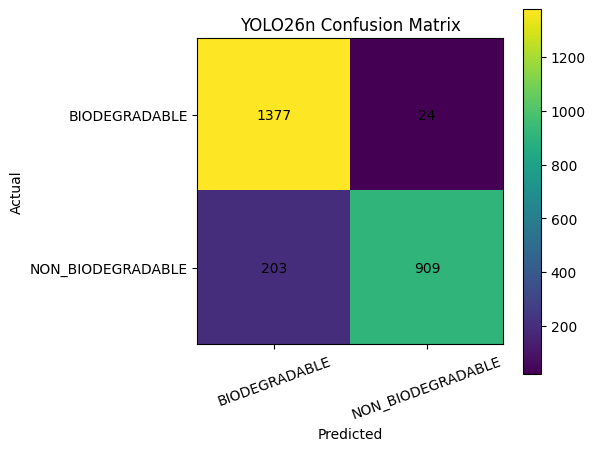

In [29]:
cm = confusion_matrix(
    true_labels,
    pred_labels
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("YOLO26n Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    range(len(classes)),
    classes,
    rotation=20
)

plt.yticks(
    range(len(classes)),
    classes
)

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [30]:
image_path = test_images[0]

result = best_model.predict(
    source=image_path,
    verbose=False
)[0]

class_id = result.probs.top1
confidence = float(result.probs.top1conf)

class_name = result.names[class_id]

print("Image:", image_path)
print("Prediction:", class_name)
print("Confidence:", f"{confidence * 100:.2f}%")

Image: /content/yolo26_waste/test/NON_BIODEGRADABLE/R_10222.jpg
Prediction: BIODEGRADABLE
Confidence: 95.05%


In [31]:
if class_name == "BIODEGRADABLE":
    print("BIODEGRADABLE")
else:
    print("NON-BIODEGRADABLE")

BIODEGRADABLE


In [32]:
from google.colab import files

uploaded = files.upload()

Saving biodegradable.jpg to biodegradable.jpg


In [33]:
uploaded_file = list(uploaded.keys())[0]

result = best_model.predict(
    source=uploaded_file,
    verbose=False
)[0]

class_id = result.probs.top1
confidence = float(result.probs.top1conf)

class_name = result.names[class_id]

print("\n==============================")
print("      WASTE CLASSIFICATION")
print("==============================")

print("Prediction :", class_name)
print("Confidence :", f"{confidence * 100:.2f}%")

if class_name == "BIODEGRADABLE":
    print("\nFINAL RESULT: BIODEGRADABLE")
else:
    print("\nFINAL RESULT: NON-BIODEGRADABLE")


      WASTE CLASSIFICATION
Prediction : BIODEGRADABLE
Confidence : 100.00%

FINAL RESULT: BIODEGRADABLE


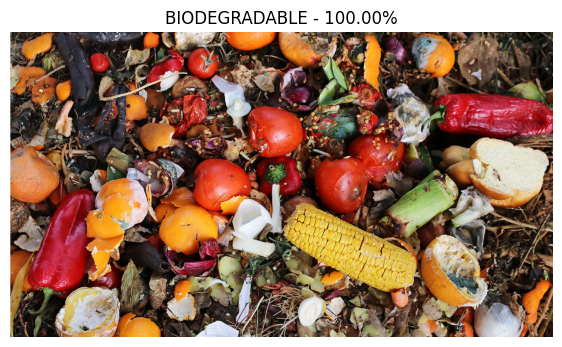

In [34]:
from PIL import Image

img = Image.open(uploaded_file)

plt.figure(figsize=(7, 7))
plt.imshow(img)
plt.axis("off")

plt.title(
    f"{class_name} - "
    f"{confidence * 100:.2f}%"
)

plt.show()

In [35]:
result.probs.top1
result.probs.top1conf

tensor(1.0000, device='cuda:0')

In [36]:
from google.colab import files

uploaded = files.upload()

Saving non_biodegradable.jpg to non_biodegradable.jpg


In [37]:
uploaded_file = list(uploaded.keys())[0]

result = best_model.predict(
    source=uploaded_file,
    verbose=False
)[0]

class_id = result.probs.top1
confidence = float(result.probs.top1conf)

class_name = result.names[class_id]

print("\n==============================")
print("      WASTE CLASSIFICATION")
print("==============================")

print("Prediction :", class_name)
print("Confidence :", f"{confidence * 100:.2f}%")

if class_name == "BIODEGRADABLE":
    print("\nFINAL RESULT: BIODEGRADABLE")
else:
    print("\nFINAL RESULT: NON-BIODEGRADABLE")


      WASTE CLASSIFICATION
Prediction : NON_BIODEGRADABLE
Confidence : 99.63%

FINAL RESULT: NON-BIODEGRADABLE


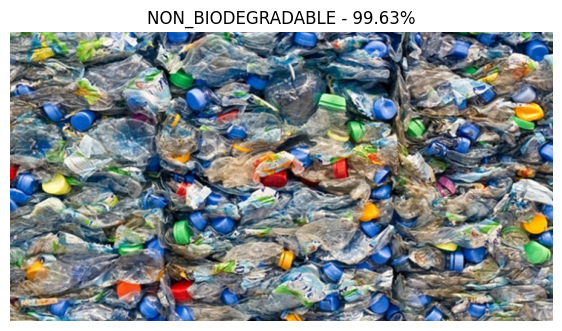

In [38]:
from PIL import Image

img = Image.open(uploaded_file)

plt.figure(figsize=(7, 7))
plt.imshow(img)
plt.axis("off")

plt.title(
    f"{class_name} - "
    f"{confidence * 100:.2f}%"
)

plt.show()

In [39]:
result.probs.top1
result.probs.top1conf

tensor(0.9963, device='cuda:0')